In [7]:
   !pip install xgboost -q


## Dataset Check

In [8]:
import pandas as pd
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)

(7043, 21)


## Setup and Imports

In [9]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
os.makedirs("plots", exist_ok=True)
sns.set_theme(style="whitegrid")


def make_preprocessor(X):
    """Missing values fill + numeric scale + categorical encode"""
    num_cols = X.select_dtypes(include=np.number).columns.tolist()
    cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])

print("Setup complete")

Setup complete


## Part 1: Data Preprocessing

In [10]:
# 1.1 Load the dataset
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
df.info()

# 1.2 Handle missing values
# TotalCharges mein blank spaces hain, isliye text se number banao (blank -> NaN)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
# NaN ko median se fill karna pipeline ke andar hoga (data leakage se bachne ke liye)

# 1.3 Remove duplicates
dups = df.duplicated().sum()
df = df.drop_duplicates()
print(f"\nDuplicates removed: {dups} | Shape now: {df.shape}")

# customerID ka koi faida nahi, hata do
df = df.drop(columns=["customerID"])

# Feature engineering (2 nayi columns)
df["AvgMonthlySpend"] = df["TotalCharges"] / df["tenure"].replace(0, np.nan)
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-1yr", "1-2yr", "2-4yr", "4-6yr"]).astype(str)

# 1.4 Target aur features alag karo
y = df["Churn"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["Churn"])

# 1.5 Train/Test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## Exploratory Data Analysis


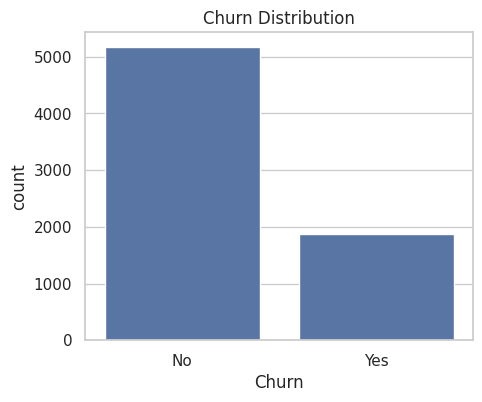

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


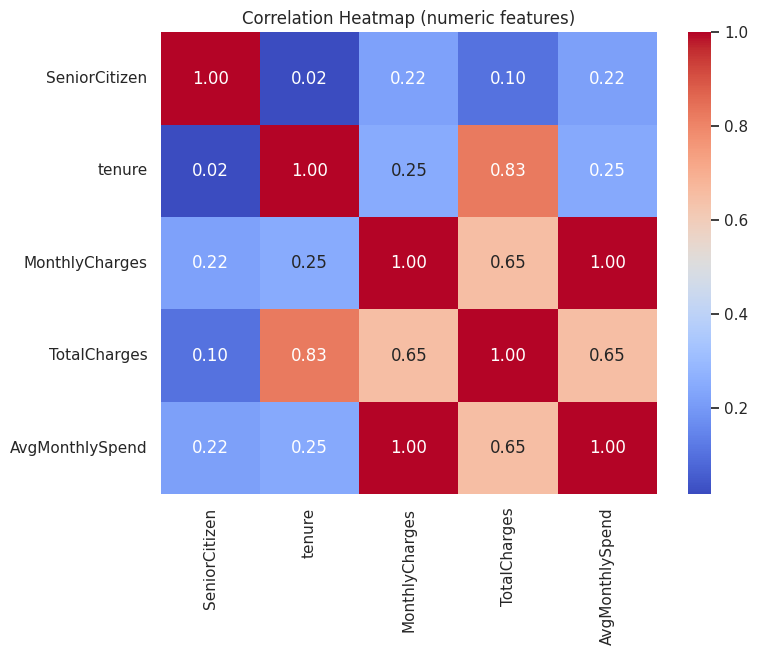

In [11]:
# Churn distribution
plt.figure(figsize=(5, 4))
sns.countplot(x="Churn", data=df)
plt.title("Churn Distribution")
plt.savefig("plots/01_churn_distribution.png", dpi=120)
plt.show()
print(df["Churn"].value_counts(normalize=True).round(3))

# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (numeric features)")
plt.savefig("plots/02_correlation_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

## Part 2 & 3: Model Development and Evaluation

Logistic Regression  acc=0.7991  f1=0.5782  time=0.15s
Decision Tree        acc=0.7339  f1=0.5059  time=0.21s
Random Forest        acc=0.7842  f1=0.5529  time=1.08s
KNN                  acc=0.7573  f1=0.5464  time=0.10s
SVM                  acc=0.7885  f1=0.5344  time=2.86s
XGBoost              acc=0.7821  f1=0.5492  time=1.21s


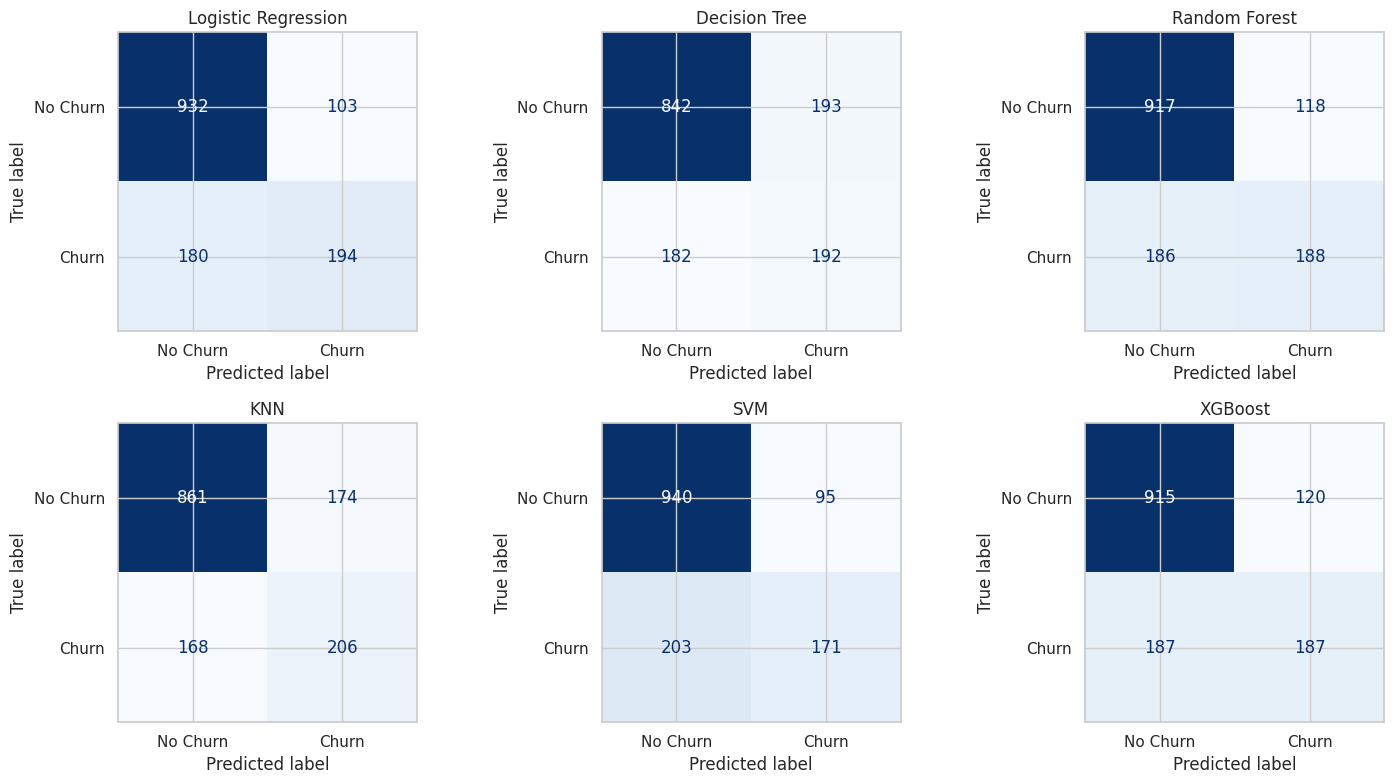

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE),
}

results, fitted, cms = [], {}, {}
for name, model in models.items():
    pipe = Pipeline([("prep", make_preprocessor(X_train)), ("model", model)])
    t0 = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - t0
    pred = pipe.predict(X_test)
    results.append({
        "Model Name": name,
        "Training Time (s)": round(train_time, 3),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
    })
    fitted[name] = pipe
    cms[name] = confusion_matrix(y_test, pred)
    print(f"{name:20s} acc={results[-1]['Accuracy']:.4f}  f1={results[-1]['F1 Score']:.4f}  time={train_time:.2f}s")

# Confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, cm) in zip(axes.ravel(), cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["No Churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("plots/03_confusion_matrices.png", dpi=120)
plt.show()

## Part 4: Model Comparison

,Model Name,Training Time (s),Accuracy,Precision,Recall,F1 Score,Advantages,Limitations
0,Logistic Regression,0.154,0.7991,0.6532,0.5187,0.5782,"Fast, simple, interpretable, good baseline","Assumes linear relationship, weak on complex patterns"
1,Random Forest,1.082,0.7842,0.6144,0.5027,0.5529,"High accuracy, robust to overfitting, gives feature importance","Slower, less interpretable, larger memory"
2,XGBoost,1.214,0.7821,0.6091,0.5000,0.5492,"Very high accuracy, handles imbalance well","Many hyperparameters, can overfit if not tuned"
3,KNN,0.098,0.7573,0.5421,0.5508,0.5464,"Simple, no training phase, works on non-linear data","Slow prediction on big data, sensitive to scaling/outliers"
4,SVM,2.859,0.7885,0.6429,0.4572,0.5344,"Effective in high dimensions, flexible kernels","Slow on large datasets, hard to tune"
5,Decision Tree,0.207,0.7339,0.4987,0.5134,0.5059,"Easy to understand/visualize, handles non-linear data","Overfits easily, unstable to small data changes"


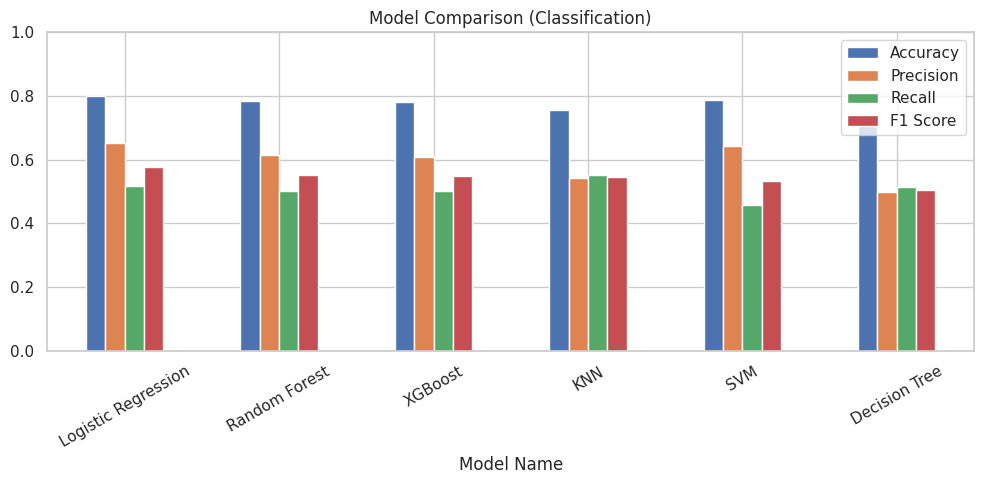

In [13]:
advantages = {
    "Logistic Regression": "Fast, simple, interpretable, good baseline",
    "Decision Tree": "Easy to understand/visualize, handles non-linear data",
    "Random Forest": "High accuracy, robust to overfitting, gives feature importance",
    "KNN": "Simple, no training phase, works on non-linear data",
    "SVM": "Effective in high dimensions, flexible kernels",
    "XGBoost": "Very high accuracy, handles imbalance well",
}
limitations = {
    "Logistic Regression": "Assumes linear relationship, weak on complex patterns",
    "Decision Tree": "Overfits easily, unstable to small data changes",
    "Random Forest": "Slower, less interpretable, larger memory",
    "KNN": "Slow prediction on big data, sensitive to scaling/outliers",
    "SVM": "Slow on large datasets, hard to tune",
    "XGBoost": "Many hyperparameters, can overfit if not tuned",
}

comp = pd.DataFrame(results)
comp["Advantages"] = comp["Model Name"].map(advantages)
comp["Limitations"] = comp["Model Name"].map(limitations)
comp = comp.sort_values("F1 Score", ascending=False).reset_index(drop=True)
comp.to_csv("model_comparison.csv", index=False)

pd.set_option("display.max_colwidth", None)
display(comp.round(4))

comp.set_index("Model Name")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(10, 5))
plt.title("Model Comparison (Classification)")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("plots/04_model_comparison.png", dpi=120)
plt.show()

## Bonus: Hyperparameter Tuning

In [14]:
tuned_results = []

# 1) Random Forest with GridSearchCV
rf_pipe = Pipeline([("prep", make_preprocessor(X_train)),
                    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
rf_grid = {"model__n_estimators": [100, 200, 300],
           "model__max_depth": [5, 10, None],
           "model__min_samples_split": [2, 5, 10]}
gs = GridSearchCV(rf_pipe, rf_grid, cv=5, scoring="f1", n_jobs=-1)
t0 = time.time(); gs.fit(X_train, y_train); t = time.time() - t0
print("RF best params:", gs.best_params_, "| CV F1:", round(gs.best_score_, 4))
tuned_results.append(("Random Forest (GridSearchCV)", gs.best_estimator_, t))

# 2) XGBoost with RandomizedSearchCV
xgb_pipe = Pipeline([("prep", make_preprocessor(X_train)),
                     ("model", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE))])
xgb_dist = {"model__n_estimators": [100, 200, 300],
            "model__max_depth": [3, 4, 5, 6],
            "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
            "model__subsample": [0.7, 0.8, 1.0]}
rs = RandomizedSearchCV(xgb_pipe, xgb_dist, n_iter=15, cv=5, scoring="f1",
                        random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time(); rs.fit(X_train, y_train); t = time.time() - t0
print("XGB best params:", rs.best_params_, "| CV F1:", round(rs.best_score_, 4))
tuned_results.append(("XGBoost (RandomizedSearchCV)", rs.best_estimator_, t))

# 3) Logistic Regression with GridSearchCV (kyunke yeh abhi best hai)
lr_pipe = Pipeline([("prep", make_preprocessor(X_train)),
                    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
lr_grid = {"model__C": [0.01, 0.1, 1, 10],
           "model__class_weight": [None, "balanced"]}
gl = GridSearchCV(lr_pipe, lr_grid, cv=5, scoring="f1", n_jobs=-1)
t0 = time.time(); gl.fit(X_train, y_train); t = time.time() - t0
print("LR best params:", gl.best_params_, "| CV F1:", round(gl.best_score_, 4))
tuned_results.append(("Logistic Regression (GridSearchCV)", gl.best_estimator_, t))

# Test set par evaluate karo
rows_t = []
for name, est, t in tuned_results:
    pred = est.predict(X_test)
    rows_t.append({"Model Name": name, "Training Time (s)": round(t, 2),
                   "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                   "Recall": recall_score(y_test, pred), "F1 Score": f1_score(y_test, pred)})
tuned_df = pd.DataFrame(rows_t)
tuned_df.to_csv("tuned_models.csv", index=False)
display(tuned_df.round(4))

RF best params: {'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 100} | CV F1: 0.5765
XGB best params: {'model__subsample': 1.0, 'model__n_estimators': 100, 'model__max_depth': 6, 'model__learning_rate': 0.05} | CV F1: 0.5776
LR best params: {'model__C': 0.01, 'model__class_weight': 'balanced'} | CV F1: 0.631


,Model Name,Training Time (s),Accuracy,Precision,Recall,F1 Score
0,Random Forest (GridSearchCV),180.33,0.8006,0.6587,0.5160,0.5787
1,XGBoost (RandomizedSearchCV),25.50,0.7970,0.6457,0.5214,0.5769
2,Logistic Regression (GridSearchCV),4.66,0.7452,0.5131,0.7861,0.6209


## Feature Importance

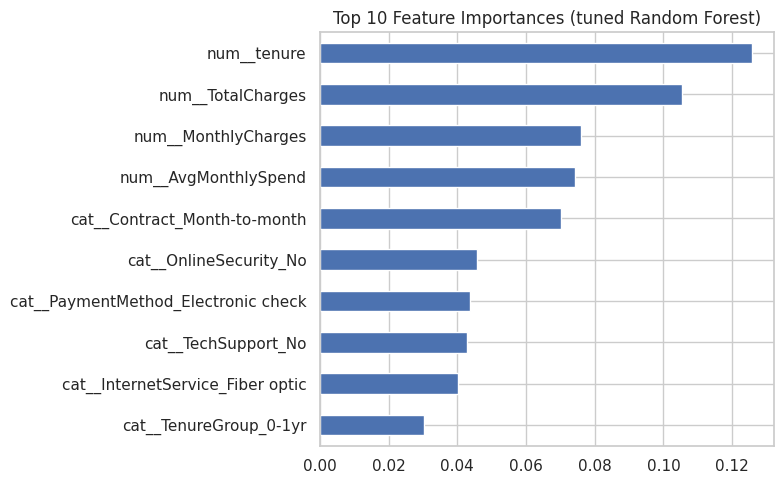

In [15]:
best_rf = tuned_results[0][1]
names = best_rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_rf.named_steps["model"].feature_importances_, index=names).nlargest(10)
plt.figure(figsize=(8, 5))
imp[::-1].plot(kind="barh")
plt.title("Top 10 Feature Importances (tuned Random Forest)")
plt.tight_layout()
plt.savefig("plots/05_feature_importance.png", dpi=120)
plt.show()


## Regression Models (MAE, MSE, RMSE, R2)

In [16]:
dfr = df.dropna(subset=["TotalCharges"])
y_r = dfr["TotalCharges"]
X_r = dfr.drop(columns=["TotalCharges", "Churn", "AvgMonthlySpend"])  # target leakage se bachne ke liye
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_r, y_r, test_size=0.2, random_state=RANDOM_STATE)

reg_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    "KNN": KNeighborsRegressor(),
    "SVM (SVR)": TransformedTargetRegressor(SVR(C=10), transformer=StandardScaler()),
    "XGBoost": XGBRegressor(random_state=RANDOM_STATE),
}

reg_rows = []
for name, m in reg_models.items():
    pipe = Pipeline([("prep", make_preprocessor(Xr_tr)), ("model", m)])
    t0 = time.time(); pipe.fit(Xr_tr, yr_tr); tt = time.time() - t0
    p = pipe.predict(Xr_te)
    mse = mean_squared_error(yr_te, p)
    reg_rows.append({"Model Name": name, "Training Time (s)": round(tt, 3),
                     "MAE": mean_absolute_error(yr_te, p), "MSE": mse,
                     "RMSE": np.sqrt(mse), "R2 Score": r2_score(yr_te, p)})

reg_df = pd.DataFrame(reg_rows).sort_values("R2 Score", ascending=False).reset_index(drop=True)
reg_df.to_csv("regression_comparison.csv", index=False)
display(reg_df.round(4))

,Model Name,Training Time (s),MAE,MSE,RMSE,R2 Score
0,Random Forest,3.790,54.3037,6748.4042,82.1487,0.9987
1,XGBoost,0.247,61.5797,8102.0965,90.0116,0.9984
2,Decision Tree,0.154,86.2991,16051.2847,126.6937,0.9969
3,SVM (SVR),0.277,109.4218,18321.0063,135.3551,0.9965
4,KNN,0.060,268.9870,171684.4764,414.3483,0.9668
5,Linear Regression,0.223,523.9424,433085.7517,658.0925,0.9162


In [17]:
advantages["Linear Regression"] = "Fast, simple, interpretable baseline for numeric targets"
limitations["Linear Regression"] = "Assumes linear relationship, sensitive to outliers"

key = reg_df["Model Name"].str.replace(" (SVR)", "", regex=False)
reg_df["Advantages"] = key.map(advantages)
reg_df["Limitations"] = key.map(limitations)
reg_df.to_csv("regression_comparison.csv", index=False)
pd.set_option("display.max_colwidth", None)
display(reg_df.round(4))

,Model Name,Training Time (s),MAE,MSE,RMSE,R2 Score,Advantages,Limitations
0,Random Forest,3.790,54.3037,6748.4042,82.1487,0.9987,"High accuracy, robust to overfitting, gives feature importance","Slower, less interpretable, larger memory"
1,XGBoost,0.247,61.5797,8102.0965,90.0116,0.9984,"Very high accuracy, handles imbalance well","Many hyperparameters, can overfit if not tuned"
2,Decision Tree,0.154,86.2991,16051.2847,126.6937,0.9969,"Easy to understand/visualize, handles non-linear data","Overfits easily, unstable to small data changes"
3,SVM (SVR),0.277,109.4218,18321.0063,135.3551,0.9965,"Effective in high dimensions, flexible kernels","Slow on large datasets, hard to tune"
4,KNN,0.060,268.9870,171684.4764,414.3483,0.9668,"Simple, no training phase, works on non-linear data","Slow prediction on big data, sensitive to scaling/outliers"
5,Linear Regression,0.223,523.9424,433085.7517,658.0925,0.9162,"Fast, simple, interpretable baseline for numeric targets","Assumes linear relationship, sensitive to outliers"



## Final Comparison

In [18]:
cols = ["Model Name", "Accuracy", "Precision", "Recall", "F1 Score"]
all_cls = pd.concat([comp[cols], tuned_df[cols]]).sort_values("F1 Score", ascending=False).reset_index(drop=True)
all_cls.to_csv("final_classification_comparison.csv", index=False)
display(all_cls.round(4))

best = all_cls.iloc[0]
print(f"Best classification model (by F1): {best['Model Name']}  F1={best['F1 Score']:.4f}  Recall={best['Recall']:.4f}")
print(f"Best regression model (by R2): {reg_df.iloc[0]['Model Name']}  R2={reg_df.iloc[0]['R2 Score']:.4f}")


,Model Name,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression (GridSearchCV),0.7452,0.5131,0.7861,0.6209
1,Random Forest (GridSearchCV),0.8006,0.6587,0.5160,0.5787
2,Logistic Regression,0.7991,0.6532,0.5187,0.5782
3,XGBoost (RandomizedSearchCV),0.7970,0.6457,0.5214,0.5769
4,Random Forest,0.7842,0.6144,0.5027,0.5529
5,XGBoost,0.7821,0.6091,0.5000,0.5492
6,KNN,0.7573,0.5421,0.5508,0.5464
7,SVM,0.7885,0.6429,0.4572,0.5344
8,Decision Tree,0.7339,0.4987,0.5134,0.5059


Best classification model (by F1): Logistic Regression (GridSearchCV)  F1=0.6209  Recall=0.7861
Best regression model (by R2): Random Forest  R2=0.9987


## Part 5: Conclusion

I trained six models (Logistic Regression, Decision Tree, Random Forest, KNN, SVM, XGBoost) on the Telco Customer Churn dataset (7,043 records). Since only 26.5% of customers churn, accuracy alone is misleading, so I compared models using Precision, Recall and F1 Score.

With default settings, Logistic Regression performed best (Accuracy 0.7991, F1 0.5782) and trained fastest. After hyperparameter tuning, the tuned Random Forest reached the highest accuracy (0.8006), while the tuned Logistic Regression achieved the highest F1 score (0.6209) and Recall (0.7861), catching about 79% of churning customers.

Recommended model: tuned Logistic Regression, because in churn prediction the main goal is to identify customers who are about to leave, and it is fast and interpretable. Its trade-off is lower accuracy (0.7452) and precision (0.5131), meaning some loyal customers are flagged by mistake. If the business prefers fewer false alarms, the tuned Random Forest is a good alternative.

Feature importance showed that tenure, total/monthly charges, month-to-month contracts, missing online security/tech support and fiber optic internet are the strongest drivers of churn.

For the regression task (predicting TotalCharges), Random Forest performed best (R2 = 0.9987, RMSE = 82.15), while Linear Regression was weakest (R2 = 0.9162) because TotalCharges is roughly tenure x MonthlyCharges, a non-linear relationship.

In [19]:
!zip -r results.zip plots model_comparison.csv tuned_models.csv regression_comparison.csv final_classification_comparison.csv
from google.colab import files
files.download("results.zip")

  adding: plots/ (stored 0%)
  adding: plots/04_model_comparison.png (deflated 18%)
  adding: plots/05_feature_importance.png (deflated 18%)
  adding: plots/01_churn_distribution.png (deflated 21%)
  adding: plots/02_correlation_heatmap.png (deflated 12%)
  adding: plots/03_confusion_matrices.png (deflated 19%)
  adding: model_comparison.csv (deflated 39%)
  adding: tuned_models.csv (deflated 32%)
  adding: regression_comparison.csv (deflated 37%)
  adding: final_classification_comparison.csv (deflated 46%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>